# Project 25 — Air Quality Estimator
## Regression vs. Neural Networks

**Goal:** Estimate the *same-hour* nitrogen dioxide concentration `NO2(GT)` (µg/m³) from five sensor readings, temperature, humidity, and calendar features. This is **estimation**, not forecasting.

**Models:** Linear Regression, degree-2 Polynomial Regression, small Keras neural network.

**Method:** chronological 80/20 holdout; 3-fold K-fold CV on the training period; MAE, RMSE, R², diagnostics. Random K-fold CV may be optimistic because observations are adjacent in time—**use the final chronological holdout as the main assessment**.

**Data:** UCI Air Quality (hourly measurements, 2004–2005); `-200` means missing. Other reference-analyzer pollutant columns are **not used** as inputs.

In [ ]:
%pip -q install kagglehub pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

## 1. Imports, reproducibility, and download

In [ ]:
from pathlib import Path
import json, random, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub
import tensorflow as tf

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style='whitegrid')

path = Path(kagglehub.dataset_download('dakshbhalala/uci-air-quality-dataset'))
print('Downloaded to:', path)
print('Files:', [str(f.relative_to(path)) for f in path.rglob('*') if f.is_file()])

100%|██████████| 246k/246k [00:00<00:00, 782kB/s]

Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/dakshbhalala/uci-air-quality-dataset/versions/1
Files: ['AirQualityUCI.csv']


## 2. Read CSV and inspect structure

In [ ]:
expected = {'Date', 'Time', 'NO2(GT)', 'T', 'RH', 'AH',
            'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)',
            'PT08.S4(NO2)', 'PT08.S5(O3)'}

csv_files = list(path.rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'No CSV files found under {path}')

candidates = sorted(csv_files, key=lambda f: ('airqualityuci' not in f.name.lower(), f.name))
best = None
attempts = []
for candidate in candidates:
    for delimiter in (';', ',', '\t'):
        try:
            preview = pd.read_csv(candidate, sep=delimiter, encoding='utf-8-sig', nrows=4)
            cols = preview.columns.astype(str).str.replace('\ufeff', '', regex=False).str.strip()
            score = len(expected.intersection(cols))
            attempts.append((candidate.name, repr(delimiter), score, cols.tolist()[:4]))
            if best is None or score > best[0]:
                best = (score, candidate, delimiter)
        except (UnicodeError, pd.errors.ParserError, ValueError):
            continue

if best is None or best[0] < len(expected):
    print('CSV detection attempts:', attempts)
    raise ValueError('Could not find the expected original UCI Air Quality columns. '
                     'Please share the printed filenames and columns.')

_, csv_path, detected_sep = best

df = pd.read_csv(csv_path, sep=detected_sep, decimal=',', encoding='utf-8-sig')
df.columns = df.columns.astype(str).str.replace('\ufeff', '', regex=False).str.strip()
df = df.loc[:, ~df.columns.str.match(r'^Unnamed:')]
df = df.dropna(axis=1, how='all').dropna(axis=0, how='all').copy()

print('Loaded CSV:', csv_path.name)
print('Detected separator:', repr(detected_sep))
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
display(df.head())


Loaded CSV: AirQualityUCI.csv
Detected separator: ','
Shape: (9357, 15)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 3. Clean missing codes, impossible readings, and engineer calendar features

We treat `-200` as missing. Physically impossible readings are marked missing, not silently assigned a plausible value. Median imputation is fitted **only on training data** later. Extreme *possible* pollution values are retained (important for honest evaluation).

In [ ]:
TARGET = 'NO2(GT)'
SENSORS = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)']
WEATHER = ['T', 'RH', 'AH']
BASE_COLS = SENSORS + WEATHER
required = ['Date', 'Time', TARGET] + BASE_COLS
missing_cols = sorted(set(required) - set(df.columns))
if missing_cols:
    raise ValueError(f'Unexpected dataset columns; missing: {missing_cols}')

for col in BASE_COLS + [TARGET]:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.strip().str.replace(',', '.', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')
df[BASE_COLS + [TARGET]] = df[BASE_COLS + [TARGET]].replace(-200, np.nan)

stamp = df['Date'].astype(str).str.strip() + ' ' + df['Time'].astype(str).str.strip().str.replace('.', ':', regex=False)
df['datetime'] = pd.to_datetime(stamp, format='%d/%m/%Y %H:%M:%S', errors='coerce')
df = df.dropna(subset=['datetime', TARGET]).sort_values('datetime').reset_index(drop=True)

df.loc[~df['RH'].between(0, 100), 'RH'] = np.nan
df.loc[~df['T'].between(-30, 60), 'T'] = np.nan
df.loc[df['AH'] < 0, 'AH'] = np.nan
for c in SENSORS:
    df.loc[df[c] < 0, c] = np.nan
df = df[df[TARGET] >= 0].reset_index(drop=True)

df['hour'] = df['datetime'].dt.hour
df['weekday'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['season'] = df['month'].map({12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'})
for c, period in [('hour',24), ('weekday',7)]:
    df[f'{c}_sin'] = np.sin(2*np.pi*df[c]/period)
    df[f'{c}_cos'] = np.cos(2*np.pi*df[c]/period)
df['month_sin'] = np.sin(2*np.pi*(df['month']-1)/12)
df['month_cos'] = np.cos(2*np.pi*(df['month']-1)/12)
FEATURES = BASE_COLS + ['hour_sin','hour_cos','weekday_sin','weekday_cos','month_sin','month_cos']
print('Usable labeled rows:', len(df))
print('Missing input percentages:', (df[FEATURES].isna().mean()*100).round(2).sort_values(ascending=False))
assert len(df) > 500, 'Unexpectedly few valid observations.'
display(df[['datetime',TARGET] + FEATURES].head())

Usable labeled rows: 2910
Missing input percentages: PT08.S1(CO)      5.33
PT08.S2(NMHC)    5.33
PT08.S3(NOx)     5.33
PT08.S4(NO2)     5.33
PT08.S5(O3)      5.33
T                5.33
RH               5.33
AH               5.33
hour_sin         0.00
hour_cos         0.00
weekday_sin      0.00
weekday_cos      0.00
month_sin        0.00
month_cos        0.00
dtype: float64


,datetime,NO2(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos
0,2004-01-04 00:00:00,86.0,1143.0,825.0,986.0,1477.0,978.0,12.0,61.6,0.8593,0.000000,1.000000,-0.781831,0.62349,0.0,1.0
1,2004-01-04 01:00:00,70.0,1044.0,770.0,1031.0,1425.0,944.0,11.5,63.9,0.8652,0.258819,0.965926,-0.781831,0.62349,0.0,1.0
2,2004-01-04 02:00:00,55.0,1034.0,716.0,1085.0,1405.0,891.0,10.7,67.2,0.8630,0.500000,0.866025,-0.781831,0.62349,0.0,1.0
3,2004-01-04 04:00:00,49.0,909.0,615.0,1237.0,1322.0,790.0,10.2,66.6,0.8299,0.866025,0.500000,-0.781831,0.62349,0.0,1.0
4,2004-01-04 05:00:00,50.0,996.0,648.0,1176.0,1340.0,852.0,11.0,63.7,0.8325,0.965926,0.258819,-0.781831,0.62349,0.0,1.0


## 4. Exploratory data analysis

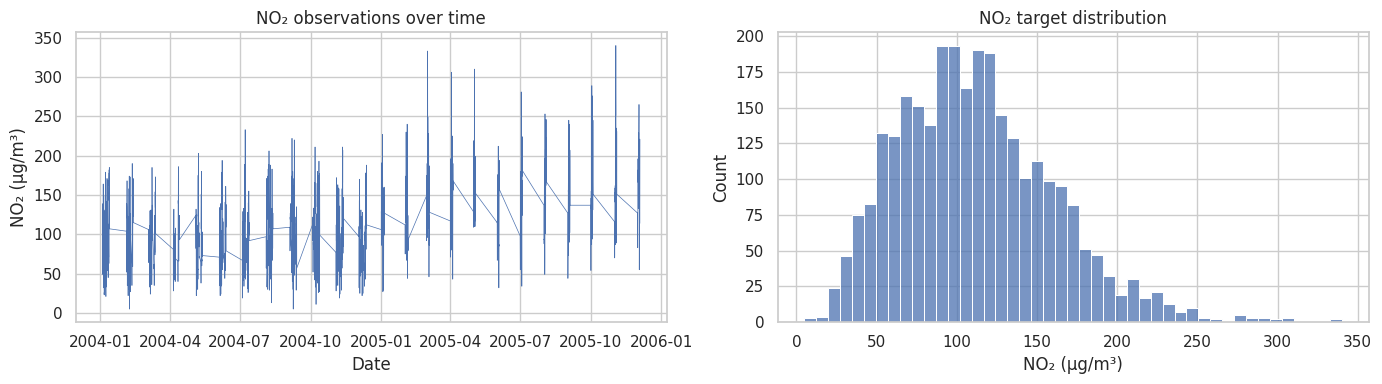

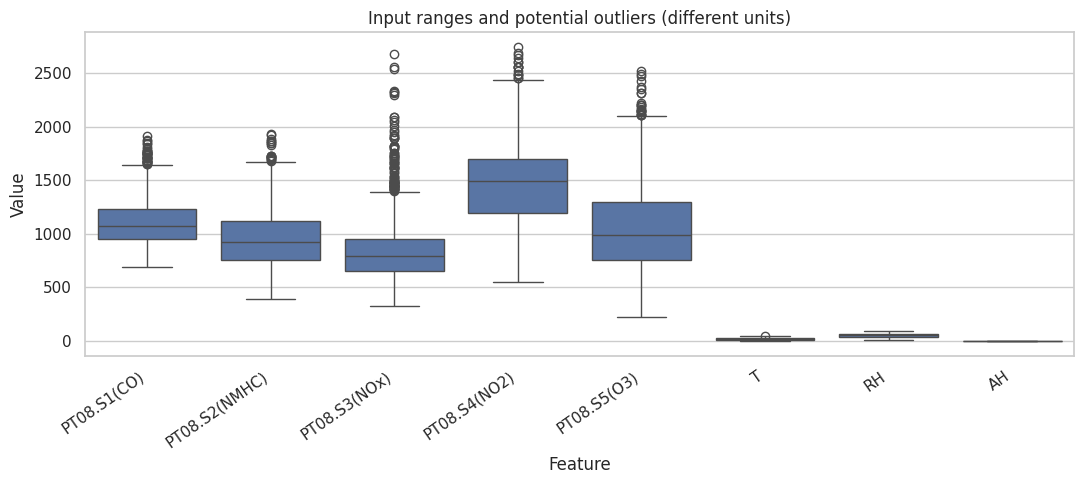

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df['datetime'], df[TARGET], lw=.5)
axes[0].set(title='NO₂ observations over time', ylabel='NO₂ (µg/m³)', xlabel='Date')
sns.histplot(df[TARGET], bins=45, ax=axes[1])
axes[1].set(title='NO₂ target distribution', xlabel='NO₂ (µg/m³)')
plt.tight_layout(); plt.show()

plt.figure(figsize=(11, 5))
sns.boxplot(data=df[BASE_COLS].melt(var_name='Feature', value_name='Value'), x='Feature', y='Value')
plt.xticks(rotation=35, ha='right'); plt.title('Input ranges and potential outliers (different units)')
plt.tight_layout(); plt.show()

## 4b. Outlier analysis (IQR)

We use the interquartile range (IQR) to **flag** unusually high/low sensor readings. We **do not automatically delete all outliers**: real pollution peaks are scientifically important. Clearly impossible values were set to missing in Section 3. Median imputation and RobustScaler reduce the influence of extreme inputs; they do not eliminate valid extreme observations.

The following is exploratory inspection only; no quantile thresholds are used to transform test data.


**Handling policy:** Impossible sensor/weather values are set to missing and imputed using training-only medians; statistical IQR outliers are flagged but preserved, since true pollution peaks should not be deleted without a domain reason. Median imputation and robust scaling reduce sensitivity to extremes.

IQR outlier counts (valid extremes retained):


,Outlier count
PT08.S3(NOx),81
PT08.S1(CO),36
PT08.S5(O3),23
PT08.S2(NMHC),18
PT08.S4(NO2),16
T,1
RH,0
AH,0


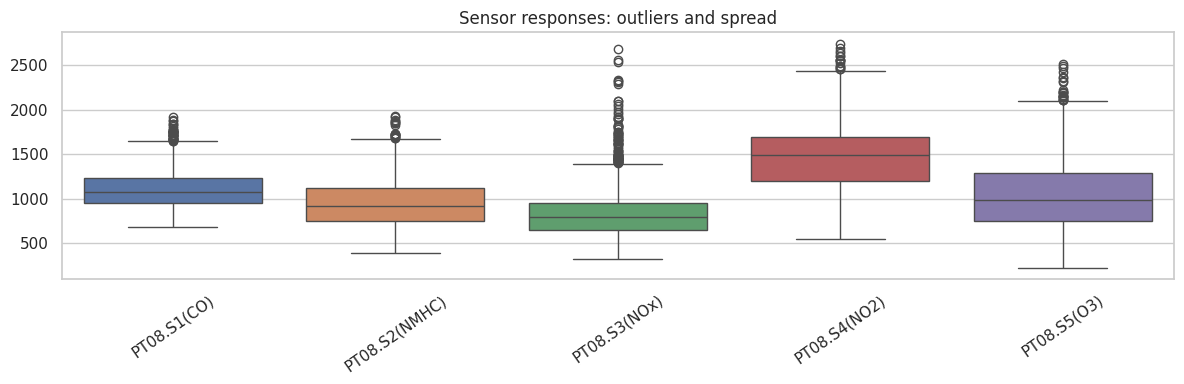

In [ ]:
q1 = df[BASE_COLS].quantile(0.25)
q3 = df[BASE_COLS].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = df[BASE_COLS].lt(lower) | df[BASE_COLS].gt(upper)
print('IQR outlier counts (valid extremes retained):')
display(outlier_flags.sum().sort_values(ascending=False).to_frame('Outlier count'))

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df[SENSORS], ax=ax)
ax.set_title('Sensor responses: outliers and spread')
ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()


## 5. Chronological train/test split (last 20% reserved)

In [ ]:
split = int(len(df)*0.8)
train_df, test_df = df.iloc[:split].copy(), df.iloc[split:].copy()
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
print('Train:', X_train.shape, train_df['datetime'].min(), 'to', train_df['datetime'].max())
print('Test: ', X_test.shape, test_df['datetime'].min(), 'to', test_df['datetime'].max())

print('Train seasons:', train_df['season'].value_counts().to_dict())
print('Test seasons:', test_df['season'].value_counts().to_dict())

Train: (2328, 14) 2004-01-04 00:00:00 to 2005-04-03 09:00:00
Test:  (582, 14) 2005-04-03 10:00:00 to 2005-12-03 23:00:00
Train seasons: {'Winter': 746, 'Autumn': 568, 'Spring': 514, 'Summer': 500}
Test seasons: {'Summer': 207, 'Autumn': 207, 'Spring': 98, 'Winter': 70}


## 6. Linear and polynomial regression + K-fold CV

The polynomial model uses degree 2. `Ridge` regularization reduces instability from many correlated polynomial terms. Preprocessing remains *inside the pipeline*, so CV folds never see their validation values during imputation or scaling.

In [ ]:
linear = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('model', LinearRegression())
])
polynomial = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', Ridge(alpha=100.0))
])
models = {'Linear Regression': linear, 'Polynomial Regression': polynomial}
kfold = KFold(n_splits=3, shuffle=False)
scoring = {'MAE':'neg_mean_absolute_error', 'RMSE':'neg_root_mean_squared_error', 'R2':'r2'}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=kfold, scoring=scoring, n_jobs=-1)
    cv_rows.append({'Model':name, 'CV MAE':-scores['test_MAE'].mean(),
                    'CV RMSE':-scores['test_RMSE'].mean(), 'CV R2':scores['test_R2'].mean()})
    model.fit(X_train, y_train)
cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

,Model,CV MAE,CV RMSE,CV R2
0,Linear Regression,24.714,32.005,0.393
1,Polynomial Regression,25.537,33.212,0.333


## 6b. Linear regression solved manually with the Normal Equation

The normal-equation least-squares solution can be computed with the Moore–Penrose pseudoinverse: **θ = X⁺y**. The pseudoinverse is numerically safer than directly inverting XᵀX. An intercept column is added to the same imputed and scaled inputs that `LinearRegression` uses. Compare the two sets of predictions to verify the implementation.


In [ ]:
Xtr_clean = linear.named_steps['imputer'].transform(X_train)
Xtr_scaled = linear.named_steps['scaler'].transform(Xtr_clean)
Xte_clean = linear.named_steps['imputer'].transform(X_test)
Xte_scaled = linear.named_steps['scaler'].transform(Xte_clean)

Xtr_design = np.c_[np.ones(len(Xtr_scaled)), Xtr_scaled]
Xte_design = np.c_[np.ones(len(Xte_scaled)), Xte_scaled]
theta_normal = np.linalg.pinv(Xtr_design) @ y_train.to_numpy()
normal_eq_pred = Xte_design @ theta_normal
sklearn_pred = linear.predict(X_test)

print('Normal Equation coefficients (intercept first):', np.round(theta_normal, 3))
print('Maximum difference from sklearn LinearRegression:', np.max(np.abs(normal_eq_pred - sklearn_pred)))
print('Normal Equation holdout MAE:', mean_absolute_error(y_test, np.maximum(normal_eq_pred, 0)))


Normal Equation coefficients (intercept first): [100.148  -1.     20.534  -6.206 -12.067  22.066  10.107   2.954 -24.614
 -14.587  -4.605   0.991   0.882   3.694   2.95 ]
Maximum difference from sklearn LinearRegression: 3.694822225952521e-13
Normal Equation holdout MAE: 29.57245249582986


## 7. Train small fully connected neural network

We use a **separate preprocessing pipeline** fitted on training data. A train/validation split from the training period is used for early stopping. Test data remains untouched.

Selected NN training epochs from validation: 88


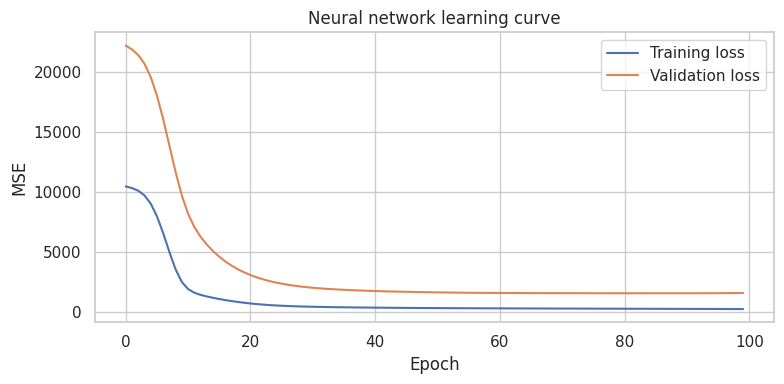

In [ ]:
validation_start = int(len(X_train) * 0.85)
train_part = X_train.iloc[:validation_start]
valid_part = X_train.iloc[validation_start:]
validation_prep = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
X_fit_nn = validation_prep.fit_transform(train_part).astype('float32')
X_valid_nn = validation_prep.transform(valid_part).astype('float32')

def build_nn(n_features):
    network = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1)
    ])
    network.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    return network

net_for_validation = build_nn(len(FEATURES))
history = net_for_validation.fit(
    X_fit_nn, y_train.iloc[:validation_start].to_numpy(dtype='float32'),
    validation_data=(X_valid_nn, y_train.iloc[validation_start:].to_numpy(dtype='float32')),
    epochs=120, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)]
)
chosen_epochs = max(1, int(np.argmin(history.history['val_loss'])) + 1)
print('Selected NN training epochs from validation:', chosen_epochs)
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Neural network learning curve'); plt.legend()
plt.tight_layout(); plt.savefig('nn_learning_curve.png',dpi=150); plt.show()

nn_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
X_train_nn = nn_preprocessor.fit_transform(X_train).astype('float32')
X_test_nn = nn_preprocessor.transform(X_test).astype('float32')
tf.keras.backend.clear_session()
net = build_nn(len(FEATURES))
net.fit(X_train_nn, y_train.to_numpy(dtype='float32'),
        epochs=chosen_epochs, batch_size=64, verbose=0)


## 8. Neural network K-fold cross-validation (3 folds)

This retrains a *fresh* network per fold. It takes longer than linear-model CV. A small internal 15% validation split from each training fold controls early stopping. As with standard K-fold CV, chronological dependencies can produce optimistic CV estimates.

In [ ]:
nn_cv = []
for fold, (tr_idx, val_idx) in enumerate(kfold.split(X_train), start=1):
    tf.keras.backend.clear_session()
    prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())])
    Xtr = prep.fit_transform(X_train.iloc[tr_idx]).astype('float32')
    Xval = prep.transform(X_train.iloc[val_idx]).astype('float32')
    ytr = y_train.iloc[tr_idx].to_numpy(dtype='float32')
    yval = y_train.iloc[val_idx].to_numpy(dtype='float32')
    model = build_nn(len(FEATURES))
    model.fit(Xtr, ytr, epochs=90, batch_size=64, verbose=0,
              validation_split=0.15, shuffle=False,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    pred = model.predict(Xval, verbose=0).ravel()
    nn_cv.append({'MAE':mean_absolute_error(yval,pred),
                  'RMSE':np.sqrt(mean_squared_error(yval,pred)), 'R2':r2_score(yval,pred)})
    print(f'Fold {fold}: {nn_cv[-1]}')
cv_table = pd.concat([cv_table, pd.DataFrame([{
    'Model':'Neural Network', 'CV MAE':np.mean([z['MAE'] for z in nn_cv]),
    'CV RMSE':np.mean([z['RMSE'] for z in nn_cv]), 'CV R2':np.mean([z['R2'] for z in nn_cv])
}])], ignore_index=True)
display(cv_table.round(3))

Fold 1: {'MAE': 16.973621368408203, 'RMSE': np.float64(21.59723128481801), 'R2': 0.6280645132064819}
Fold 2: {'MAE': 20.50348663330078, 'RMSE': np.float64(25.025053364547247), 'R2': 0.5891780853271484}
Fold 3: {'MAE': 24.17523765563965, 'RMSE': np.float64(32.90909517020903), 'R2': 0.5702414512634277}


,Model,CV MAE,CV RMSE,CV R2
0,Linear Regression,24.714,32.005,0.393
1,Polynomial Regression,25.537,33.212,0.333
2,Neural Network,20.551,26.510,0.596


## 9. Final independent holdout evaluation

All three models are evaluated on **exactly the same final chronological test period**. Neural-network predictions refer to the model trained in section 7 (not a fold model).

In [ ]:
predictions = {
    'Linear Regression': linear.predict(X_test),
    'Polynomial Regression': polynomial.predict(X_test),
    'Neural Network': net.predict(X_test_nn, verbose=0).ravel()
}
predictions = {k:np.maximum(v,0) for k,v in predictions.items()}
results = pd.DataFrame([
    {'Model': name, 'MAE':mean_absolute_error(y_test, pred),
     'RMSE':np.sqrt(mean_squared_error(y_test, pred)),
     'R2':r2_score(y_test, pred)}
    for name,pred in predictions.items()
]).sort_values('RMSE').reset_index(drop=True)
print('Chronological TEST results (lower MAE/RMSE is better, higher R² is better):')
display(results.round(3))
print('K-fold training-period CV (different evaluation protocol):')
display(cv_table.round(3))
best_name = cv_table.sort_values('CV RMSE').iloc[0]['Model']
print('Model selected using TRAIN CV RMSE:', best_name)
print('Test metrics are reported for evaluation only, not model selection.')

Chronological TEST results (lower MAE/RMSE is better, higher R² is better):


,Model,MAE,RMSE,R2
0,Polynomial Regression,28.382,45.933,0.201
1,Linear Regression,29.572,47.140,0.158
2,Neural Network,29.378,47.534,0.144


K-fold training-period CV (different evaluation protocol):


,Model,CV MAE,CV RMSE,CV R2
0,Linear Regression,24.714,32.005,0.393
1,Polynomial Regression,25.537,33.212,0.333
2,Neural Network,20.551,26.510,0.596


Model selected using TRAIN CV RMSE: Neural Network
Test metrics are reported for evaluation only, not model selection.


## 10. Predicted vs actual and residual plots

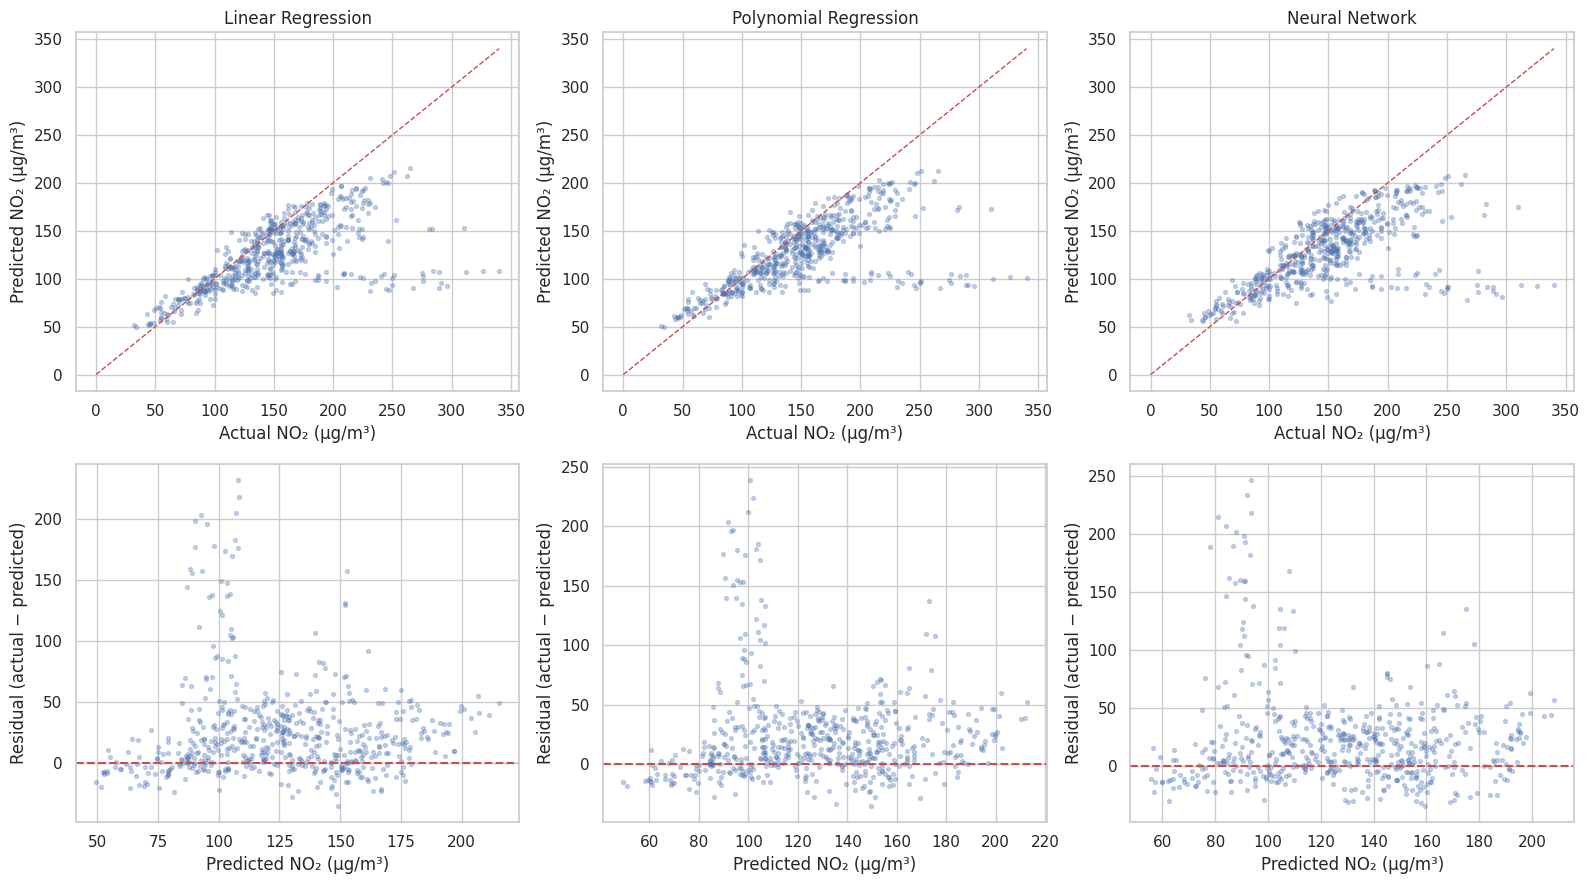

In [ ]:
fig, axes = plt.subplots(2,3,figsize=(16,9))
for col,(name,pred) in enumerate(predictions.items()):
    axes[0,col].scatter(y_test,pred,alpha=.3,s=8)
    lim=max(float(y_test.max()),float(np.max(pred)))
    axes[0,col].plot([0,lim],[0,lim],'r--',lw=1)
    axes[0,col].set(title=name, xlabel='Actual NO₂ (µg/m³)', ylabel='Predicted NO₂ (µg/m³)')
    residuals=y_test.to_numpy()-pred
    axes[1,col].scatter(pred,residuals,alpha=.3,s=8)
    axes[1,col].axhline(0,color='r',ls='--')
    axes[1,col].set(xlabel='Predicted NO₂ (µg/m³)',ylabel='Residual (actual − predicted)')
plt.tight_layout();plt.savefig('predictions_residuals.png', dpi=150);plt.show()

## 11. Error by hour and season

Seasonal conclusions should be qualified: the chronological test split may not contain every season.

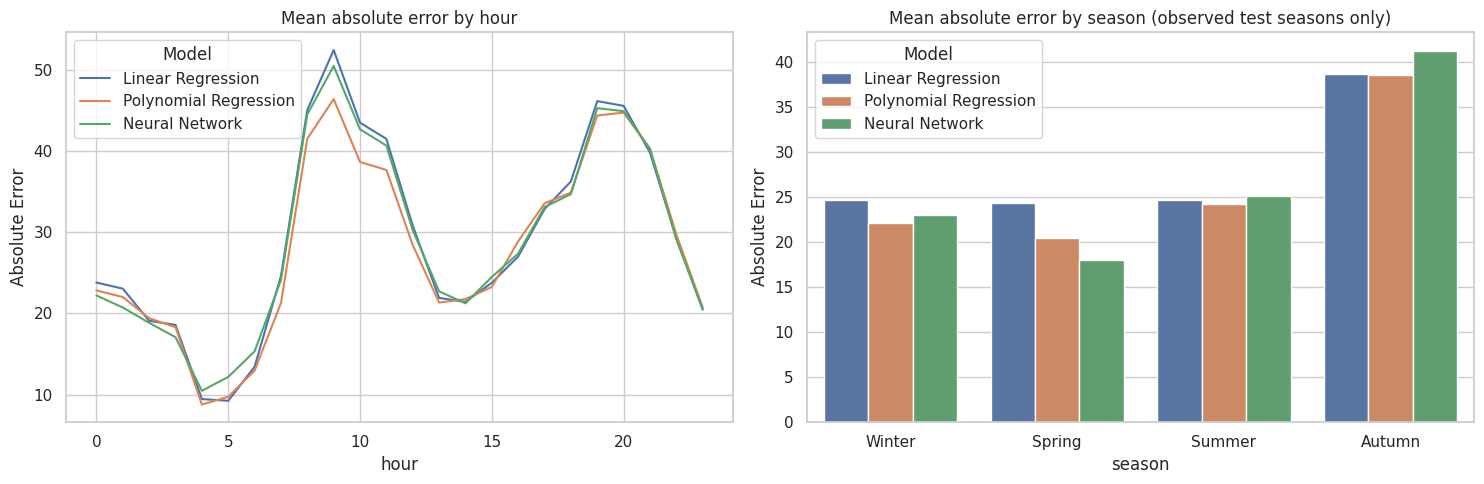

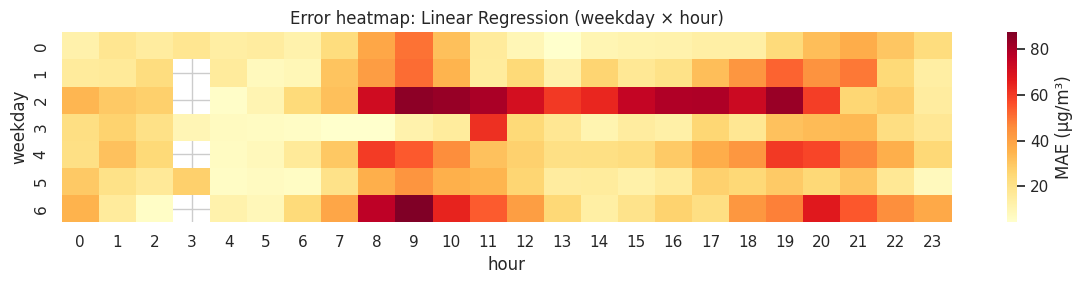

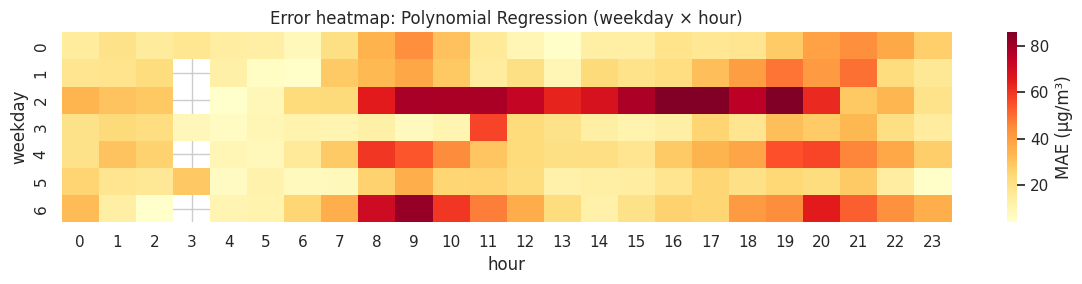

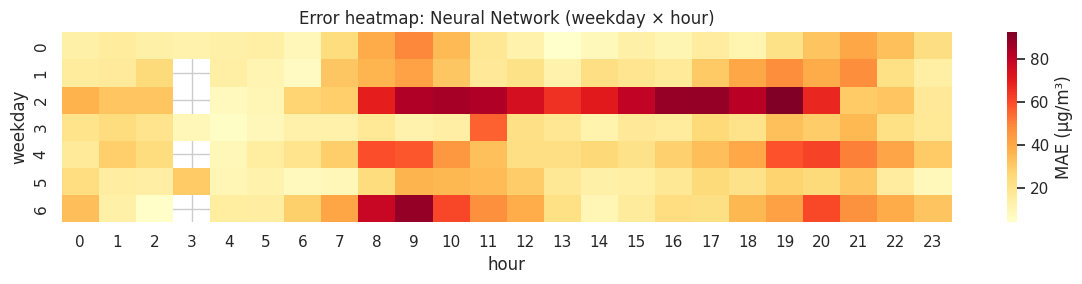

In [ ]:
err = test_df[['datetime','hour','season']].copy()
for name,pred in predictions.items():
    err[name] = abs(y_test.to_numpy()-pred)
long = err.melt(id_vars=['datetime','hour','season'], var_name='Model', value_name='Absolute Error')
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.lineplot(data=long, x='hour', y='Absolute Error', hue='Model', estimator='mean', errorbar=None, ax=axes[0])
axes[0].set_title('Mean absolute error by hour')
order = ['Winter','Spring','Summer','Autumn']
sns.barplot(data=long, x='season', y='Absolute Error', hue='Model', order=order, errorbar=None, ax=axes[1])
axes[1].set_title('Mean absolute error by season (observed test seasons only)')
plt.tight_layout();plt.savefig('error_by_hour_season.png', dpi=150);plt.show()

for name in predictions:
    pivot = test_df.assign(abs_error=np.abs(y_test.to_numpy()-predictions[name]))        .pivot_table(index='weekday', columns='hour', values='abs_error', aggfunc='mean')
    plt.figure(figsize=(12,3))
    sns.heatmap(pivot, cmap='YlOrRd', cbar_kws={'label':'MAE (µg/m³)'})
    plt.title(f'Error heatmap: {name} (weekday × hour)')
    plt.tight_layout();plt.savefig('error_heatmap_'+name.lower().replace(' ','_')+'.png',dpi=150);plt.show()

## 12. Save fitted models, metrics and feature specification

In [ ]:
from google.colab import files
from pathlib import Path
import zipfile
out = Path('air_quality_artifacts'); out.mkdir(exist_ok=True)
joblib.dump(linear, out/'linear.joblib')
joblib.dump(polynomial, out/'polynomial.joblib')
joblib.dump(nn_preprocessor, out/'nn_preprocessor.joblib')
net.save(out/'neural_network.keras')
cv_best = cv_table.sort_values('CV RMSE').iloc[0]['Model']
config = {'features':FEATURES,'target':TARGET,'default_model':cv_best,
          'units':'µg/m³', 'note':'Same-hour NO2 estimate, not a forecast'}
(out/'config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
results.to_csv(out/'test_metrics.csv',index=False)
import shutil
for fig in Path('.').glob('*.png'):
    if fig.name in ['nn_learning_curve.png','predictions_residuals.png','error_by_hour_season.png'] or fig.name.startswith('error_heatmap_'):
        shutil.copy2(fig,out/fig.name)
cv_table.to_csv(out/'cv_metrics.csv',index=False)
zip_name='air_quality_artifacts.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as z:
    for file in out.iterdir():
        z.write(file,arcname=file.name)
print('Default model selected on CV RMSE:',cv_best)


Default model selected on CV RMSE: Neural Network


## 13. Notes for the written report

1. **Problem:** Same-hour NO₂ regression; not a time-series forecast.
2. **Dataset:** UCI Air Quality; report the rows remaining after target filtering; explain `-200`.
3. **Preprocessing:** Input invalids → missing; training-only median imputation and robust scaling; circular calendar features.
4. **Evaluation:** Three-fold training CV plus final chronological 20% holdout. Explain how K-fold can overestimate performance with temporally autocorrelated observations.
5. **Metrics:** Explain MAE and RMSE (µg/m³) and R² (unitless).
6. **Analysis:** Discuss large residuals, hourly variation, limited season coverage in final holdout.
7. **Limitations:** Old single-city dataset, sensor drift, non-weather effects, covariate shift, interpolation limitations.
8. **Ethics:** This is an educational approximation, not a calibrated health/safety monitoring device.

**Data source:** [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality)
8. **Normal equation:** Explain the pseudoinverse calculation and agreement with scikit-learn.
9. **Outliers:** Report IQR-flagged counts, physically invalid readings removed, and why valid pollution peaks are retained.


## 14. Export final PDF report and model artifacts


In [ ]:
%pip -q install reportlab
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4
from xml.sax.saxutils import escape

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name='ReportTitleCustom',parent=styles['Title'],fontSize=19,leading=24,spaceAfter=14))
styles.add(ParagraphStyle(name='ReportBodyCustom',parent=styles['BodyText'],fontSize=10,leading=15,spaceAfter=10))
pdf_path = out/'Final_Report.pdf'
doc = SimpleDocTemplate(str(pdf_path), pagesize=A4, rightMargin=46,leftMargin=46,topMargin=45,bottomMargin=45)
story = []
def add(text, style='ReportBodyCustom'):
    story.append(Paragraph(escape(str(text)),styles[style]))

def section(text):
    story.append(Spacer(1,10)); story.append(Paragraph(escape(text),styles['Heading2']))

add('Project 25 — Air Quality Estimator', 'ReportTitleCustom')
add('Regression vs. Neural Networks | Final experimental report')
section('1. Objective and dataset')
add('Estimate same-hour NO2 concentration (µg/m3) using five chemical-sensor readings, temperature, relative humidity, absolute humidity, and cyclical calendar features. Dataset: UCI Air Quality (Kaggle mirror: dakshbhalala/uci-air-quality-dataset).')
add(f'Usable labeled records: {len(df)}. Chronological holdout: {len(test_df)} rows ({len(test_df)/len(df):.1%}); training: {len(train_df)} rows.')
section('2. Data cleaning and feature engineering')
add('Missing-value code -200 replaced with NaN; invalid targets removed; impossible physical input values marked missing. Training-only median imputation and robust scaling used in pipelines. Statistical IQR outliers were identified but retained to preserve possible real pollution episodes. Hour, weekday and month are encoded using sine/cosine functions.')
section('3. Methods and evaluation')
add('Linear Regression (including NumPy pseudoinverse normal-equation check), degree-2 Polynomial Features with Ridge regularization, and a small feedforward network (32 and 16 ReLU units). Training-period 3-fold cross-validation; untouched chronological last-20% test subset. Report MAE, RMSE, R2. Negative predictions are clipped to zero at evaluation and deployment.')
section('4. Cross-validation (training set)')
tbl = [['Model','CV MAE','CV RMSE','CV R2']]
for _,r in cv_table.iterrows(): tbl.append([r['Model'],f"{r['CV MAE']:.2f}",f"{r['CV RMSE']:.2f}",f"{r['CV R2']:.3f}"])
t=Table(tbl,colWidths=[170,94,94,80],repeatRows=1);t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#17365D')),('TEXTCOLOR',(0,0),(-1,0),colors.white),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.whitesmoke,colors.white]),('GRID',(0,0),(-1,-1),.25,colors.lightgrey),('BOTTOMPADDING',(0,0),(-1,-1),8),('TOPPADDING',(0,0),(-1,-1),8)]));story.append(t)
section('5. Holdout test results')
tbl = [['Model','MAE','RMSE','R2']]
for _,r in results.iterrows(): tbl.append([r['Model'],f"{r['MAE']:.2f}",f"{r['RMSE']:.2f}",f"{r['R2']:.3f}"])
t=Table(tbl,colWidths=[170,94,94,80],repeatRows=1);t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#17365D')),('TEXTCOLOR',(0,0),(-1,0),colors.white),('GRID',(0,0),(-1,-1),.25,colors.lightgrey),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.whitesmoke,colors.white]),('BOTTOMPADDING',(0,0),(-1,-1),8),('TOPPADDING',(0,0),(-1,-1),8)]));story.append(t)
add(f'Model selected using training CV RMSE: {best_name}. Test set metrics were not used to select the deployed model.')
section('6. Plots and error analysis')
for filename,heading in [('predictions_residuals.png','Predicted vs. actual and residuals'),('error_by_hour_season.png','Error by hour and season'),('error_heatmap_linear_regression.png','Error heatmap: linear regression'),('nn_learning_curve.png','Neural network training curve')]:
    path_figure = out/filename
    if path_figure.exists():
        story.append(Paragraph(escape(heading),styles['Heading3']))
        from PIL import Image as PILImage
        with PILImage.open(path_figure) as im:
            w,h = im.size
        scale = min(490/w,330/h)
        story.append(Image(str(path_figure),width=w*scale,height=h*scale))
        story.append(Spacer(1,8))
section('7. Limitations and conclusion')
add('These are historical observations from one site, not a validated real-time regulatory monitor. The original measurements are hourly and temporally correlated; even an ordered train/test split does not provide independent observations, and 3-fold CV may be optimistic. Sensor drift, geography, missing observations and season coverage affect generalization. The estimate is for the same observation time, not the future.')
add(f'Conclusion: the CV-based deployment choice is {best_name}. Compare its test errors with the other models and discuss any differences from CV. Domain validation is needed before practical use.')
add('Source: UCI Machine Learning Repository, Air Quality dataset; mirrored on Kaggle by dakshbhalala.')
doc.build(story)
print('PDF generated:',pdf_path)
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as z:
    for file in out.iterdir():
        if file.is_file(): z.write(file,arcname=file.name)
print('Updated model artifacts ZIP:',zip_name)
files.download(str(pdf_path))
files.download(zip_name)


PDF generated: air_quality_artifacts/Final_Report.pdf
Updated model artifacts ZIP: air_quality_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>